# 02 – The multilingual Claudette corpus

**Why we need it:** our fairness extension asks whether consumers reading a contract in Italian, German or Polish get the same protection from our system as those reading it in English.
To measure this we need the *same* contracts, annotated by legal experts, in several languages.

The corpus (Drawzeski et al., 2021) contains **25 Terms of Service, each in English, German, Italian and Polish** (100 contracts).
Compared with UNFAIR-ToS it also has:
- an **unfairness level** per sentence: `clearly_fair`, `potentially_unfair`, `clearly_unfair` (or `untagged`);
- a 9th category, **privacy included** (`pinc`): the privacy policy is part of the contract you accept;
- the **original text** (normal casing and punctuation), and newer document versions (around 2021).

License: CC BY-NC 2.5 (non-commercial use only), fine for a university project.

Run `python scripts/download_multilingual.py` and `python scripts/prepare_multilingual_eval.py` first.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "multilingual"
PROC_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BLUE, GRAY = "#2a78d6", "#b4b2a9"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.edgecolor": INK_2, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})

def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")

CATS = {"ltd": "Limitation of liability", "ter": "Unilateral termination", "ch": "Unilateral change",
        "cr": "Content removal", "use": "Contract by using", "law": "Choice of law",
        "j": "Jurisdiction", "a": "Arbitration", "pinc": "Privacy included"}
LANGS = ["en", "de", "it", "pl"]

ml = pd.concat([pd.read_json(RAW_DIR / f"tos_multilingual_{s}.jsonl", lines=True).assign(split=s)
                for s in ["train", "validation", "test"]], ignore_index=True)
ml["unfair"] = ml["unfairness_level"].isin(["potentially_unfair", "clearly_unfair"])
print(len(ml), "sentences,", ml["company"].nunique(), "companies")
ml[["language", "company", "sentence", "unfairness_level", "all_topics"]].sample(5, random_state=0)

25929 sentences, 25 companies


,language,company,sentence,unfairness_level,all_topics
4277,de,Tripadvisor,"Director, Partnerships and Business Development",untagged,[]
19183,pl,Spotify,7 Wykonalność,untagged,[]
12798,it,Skype,L'utente riconosce e accetta che: (i) Skype no...,untagged,[]
7263,en,Quora,"Notices will be deemed given (a) if to you, wh...",untagged,[]
23140,en,Weebly,The failure of Weebly to exercise or enforce a...,untagged,[]


## 1. Are the four languages annotated in the same way?

In [2]:
per_lang = ml.groupby("language").agg(
    sentences=("sentence", "size"),
    unfair=("unfair", "sum"),
    clearly_unfair=("unfairness_level", lambda s: (s == "clearly_unfair").sum()),
    clearly_fair=("unfairness_level", lambda s: (s == "clearly_fair").sum()),
).reindex(LANGS)
per_lang["% unfair"] = (100 * per_lang["unfair"] / per_lang["sentences"]).round(1)
per_lang

,sentences,unfair,clearly_unfair,clearly_fair,% unfair
language,,,,,
en,6831,632,125,46,9.3
de,5911,587,119,49,9.9
it,6295,622,124,47,9.9
pl,6892,648,127,51,9.4


In [3]:
pd.DataFrame({CATS[c]: ml[ml["unfair"] & ml[c]].groupby("language").size() for c in CATS}).T.reindex(columns=LANGS).fillna(0).astype(int)

language,en,de,it,pl
Limitation of liability,230,213,217,230
Unilateral termination,120,118,121,124
Unilateral change,101,99,103,103
Content removal,51,48,52,52
Contract by using,58,54,58,61
Choice of law,39,33,36,36
Jurisdiction,49,46,48,50
Arbitration,33,25,33,39
Privacy included,21,17,20,21


**Why this matters:** the share of unfair sentences (9.3–9.9%) and the counts per category are almost identical across languages.
So if our system performs worse in one language, the cause is the language itself, not a different dataset.

## 2. Unfairness levels: which categories are *clearly* unfair?

In [4]:
levels = pd.DataFrame({CATS[c]: ml.loc[ml[c], "unfairness_level"].value_counts() for c in CATS}).T
levels = levels.reindex(columns=["clearly_fair", "potentially_unfair", "clearly_unfair"]).fillna(0).astype(int)
levels

unfairness_level,clearly_fair,potentially_unfair,clearly_unfair
Limitation of liability,69,853,37
Unilateral termination,0,282,201
Unilateral change,0,335,71
Content removal,0,106,97
Contract by using,0,231,0
Choice of law,68,94,50
Jurisdiction,57,0,193
Arbitration,14,115,15
Privacy included,0,79,0


**What we learn:**
- *Jurisdiction* is mostly **clearly unfair** (e.g. forcing a European consumer to sue in California), but sometimes **clearly fair** (when the consumer can sue where they live).
- *Limitation of liability* is almost always **potentially** unfair, and sometimes clearly fair (when the provider still accepts liability for fraud, death or injury).
- *Contract by using* is always potentially unfair.

The `clearly_fair` sentences are useful **hard negatives**: they are about the same topic as unfair clauses but are fair, so a system that only recognises the topic will get them wrong.
These distinctions are also exactly what a good explanation should capture, and they will guide the legal rationales in our knowledge base.

In [5]:
for level in ["clearly_fair", "clearly_unfair"]:
    print(f"=== {level} (English) ===")
    for _, r in ml[(ml["language"] == "en") & (ml["unfairness_level"] == level)].sample(3, random_state=1).iterrows():
        tags = [CATS[c] for c in CATS if r[c]]
        print(f"  [{', '.join(tags)}] {r['sentence'][:260]}")
    print()

=== clearly_fair (English) ===
  [Limitation of liability] Nothing in the Agreements removes or limits Spotify’s liability for fraud, fraudulent misrepresentation, death or personal injury caused by its negligence, and, if required by applicable law, gross negligence.
  [Jurisdiction] If you are located anywhere other than the United States, judicial proceedings must be brought in a court of competent jurisdiction in the state where you are habitually resident (“Applicable Jurisdiction”), unless the parties all agree to some other location.
  [Limitation of liability] WE DON’T EXCLUDE OR LIMIT OUR LIABILITY TO YOU WHERE IT WOULD BE ILLEGAL TO DO SO—THIS INCLUDES ANY LIABILITY FOR DROPBOX’S OR ITS AFFILIATES’ FRAUD OR FRAUDULENT MISREPRESENTATION IN PROVIDING THE SERVICES.

=== clearly_unfair (English) ===
  [Limitation of liability, Unilateral termination, Unilateral change] Spotify reserves the right, in its absolute discretion, to determine your eligibility for a Trial, and, subject 

## 3. Overlap with UNFAIR-ToS (data leakage)

Many companies appear in both datasets (often a 2017 and a 2021 version of the same contract).
`scripts/prepare_multilingual_eval.py` compared every English sentence (≥ 6 words) with all UNFAIR-ToS sentences, ignoring casing, spaces and punctuation, and marked it as a near-duplicate if the similarity is ≥ 90/100.

In [6]:
summary = json.loads((PROC_DIR / "multilingual_eval_summary.json").read_text(encoding="utf-8"))
companies = pd.DataFrame(summary["companies"]).T
companies["overlap_pct"] = companies["overlap_pct"].astype(float)
print(f"English sentences that are near-duplicates of UNFAIR-ToS: {summary['english_near_duplicates_pct']}%")
companies.sort_values("overlap_pct")

English sentences that are near-duplicates of UNFAIR-ToS: 42.1%


,overlap_pct,status
Ryanair,0.0,kept
Mozilla,0.0,kept
Terravision,0.0,"excluded: English version is a different, ~3x ..."
Quora,1.1,kept
Electronic_Arts,1.8,kept
Yelp,3.8,kept
Weebly,4.2,kept
Garmin,5.1,kept
Grindr,6.0,kept
Facebook,6.1,kept


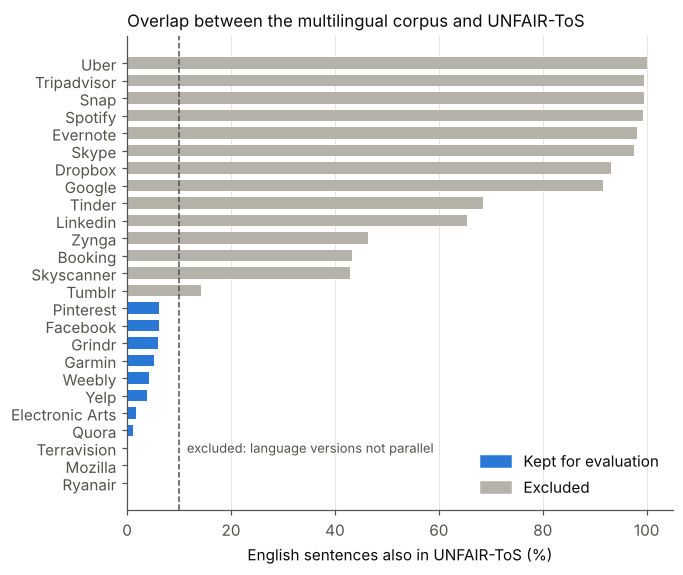

In [7]:
c = companies.sort_values("overlap_pct")
colors = [BLUE if s == "kept" else GRAY for s in c["status"]]
fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax.barh(c.index.str.replace("_", " "), c["overlap_pct"], height=0.65, color=colors)
ax.axvline(summary["settings"]["max_company_overlap_pct"], color=INK_2, linewidth=1, linestyle="--")
ax.set_xlabel("English sentences also in UNFAIR-ToS (%)")
ax.set_title("Overlap between the multilingual corpus and UNFAIR-ToS", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 105)
for y, (overlap, status) in enumerate(zip(c["overlap_pct"], c["status"])):
    if status != "kept" and overlap < summary["settings"]["max_company_overlap_pct"]:
        ax.text(summary["settings"]["max_company_overlap_pct"] + 1.5, y, "excluded: language versions not parallel", va="center", fontsize=8.5, color=INK_2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Kept for evaluation"), Patch(color=GRAY, label="Excluded")],
          frameon=False, loc="lower right")
save(fig, "multilingual_overlap")
plt.show()

**Why this matters:** for Spotify, Skype, Snap, Tripadvisor, Evernote, Uber, Google and Dropbox, more than 90% of the English sentences are already in UNFAIR-ToS.
Testing on them would test the system on sentences it was trained on (BERT) or that are in its knowledge base (RAG), and the English results would look better than they really are, which would make the language gap look **bigger** than it is.
We therefore keep only companies with < 10% overlap. Terravision is also excluded because its English version is a different, much longer document (3× more unfair clauses than in the other languages), so the four versions are not comparable.

## 4. The multilingual evaluation set

In [8]:
ev = pd.read_json(PROC_DIR / "multilingual_eval.jsonl", lines=True)
ev["unfair"] = ev["labels"].str.len() > 0
print("Companies:", ", ".join(summary["kept_companies"]))
ev.groupby("language").agg(sentences=("id", "size"), unfair=("unfair", "sum"),
                           pinc_only=("pinc_only", "sum"), in_unfair_tos=("in_unfair_tos", "sum")).reindex(LANGS)

Companies: Ryanair, Mozilla, Quora, Electronic_Arts, Yelp, Weebly, Garmin, Grindr, Facebook, Pinterest


,sentences,unfair,pinc_only,in_unfair_tos
language,,,,
en,2451,228,4,81
de,2273,219,3,0
it,2477,229,4,0
pl,2718,238,4,0


In [9]:
label_names = json.loads((PROJECT_ROOT / "data" / "raw" / "metadata.json").read_text(encoding="utf-8"))["label_names"]
rows = {lang: [sum(i in labels for labels in ev.loc[ev["language"] == lang, "labels"]) for i in range(len(label_names))]
        for lang in LANGS}
pd.DataFrame(rows, index=label_names)

,en,de,it,pl
Limitation of liability,75,76,73,76
Unilateral termination,42,42,42,43
Unilateral change,28,28,30,28
Content removal,27,26,27,28
Contract by using,21,19,22,23
Choice of law,18,17,17,18
Jurisdiction,21,21,22,21
Arbitration,21,16,21,25


In [10]:
ev[["language", "text_raw", "text", "label_names"]][ev["unfair"]].sample(4, random_state=3)

,language,text_raw,text,label_names
8241,en,If your Country of Residence is the United Kin...,if your country of residence is the united kin...,[Choice of law]
5415,pl,Wszelkie spory i roszczenia wynikające z ninie...,wszelkie spory i roszczenia wynikające z ninie...,[Arbitration]
7464,de,"Wir können jede Drittanbieterleistung, inklusi...","wir können jede drittanbieterleistung , inklus...","[Limitation of liability, Unilateral termination]"
7743,de,"Wir haben das Recht, Ihr Konto, mit oder ohne ...","wir haben das recht , ihr konto , mit oder ohn...",[Unilateral termination]


## 5. Findings and decisions

**1. Same annotations in every language.** 9.3–9.9% of sentences are unfair in each language, with almost the same counts per category, so a performance gap between languages can be attributed to the language.

**2. Strong overlap with UNFAIR-ToS.** 42% of the English sentences are near-duplicates of UNFAIR-ToS sentences, concentrated in 13 companies (up to 100%).
→ *Decision:* evaluate only on the **10 companies with < 10% overlap** (Electronic Arts, Facebook, Garmin, Grindr, Mozilla, Pinterest, Quora, Ryanair, Weebly, Yelp). Remaining English near-duplicates are flagged (`in_unfair_tos`) so they can be excluded.

**3. Not every company is parallel.** Terravision's English version is a different document → excluded. Sentences are not aligned one-to-one across languages (different sentence splitting), so we compare languages **at the level of the whole set**, not sentence by sentence.

**4. The evaluation set is balanced and large enough.** 219–238 unfair clauses per language (more than the 172 in the UNFAIR-ToS test set), in all 8 categories.

**5. Label mapping.** A sentence is unfair if its level is `potentially_unfair` or `clearly_unfair`; its labels are its category tags, mapped to the 8 UNFAIR-ToS categories.
"Privacy included" does not exist in UNFAIR-ToS, so the few sentences that are unfair only for that reason (3–4 per language) are flagged (`pinc_only`) and excluded when evaluating.
*Limitation:* when a sentence has two tags, the corpus keeps only the higher level, so a tag can occasionally be marked unfair even if that part of the sentence is fair.

**6. Format difference.** This corpus keeps normal casing and punctuation, while UNFAIR-ToS is lowercased and tokenized.
→ *Decision:* the evaluation set stores both `text_raw` and `text` (normalised like UNFAIR-ToS with `claudette_rag.text.normalize_like_unfair_tos`), so every system sees the same format it was built on.

**7. Bonus for explainability.** The unfairness levels (clearly fair / potentially unfair / clearly unfair) are not in UNFAIR-ToS. They show *when* a category is clearly unfair (e.g. jurisdiction away from the consumer's home) and give hard negatives (`clearly_fair`); we will use them to write the legal rationales of the knowledge base and to check the explanations.